# 02 · OOD scenarios (synthetic covariate shift)

**Goal:** define the first family of OOD scenarios and justify the severity grid *before* any detector exists.

Design rules (see `src/conformal_trees/data/ood_scenarios.py` and `docs/decisions.md`, D6-D7):
1. Shift statistics (per-feature std) are measured on `train` only.
2. OOD sets are built by shifting rows of `test`, so ID and OOD sets are **paired** (same rows).
3. Severity is in units of the per-feature std; no clipping.
4. Integer-valued features stay integer-valued after the shift.
5. Spike-at-a-value features (mostly zeros, like `capital-gain`) are excluded by default.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from conformal_trees.data import CovariateShift, build_covariate_shifts, load_dataset, make_splits
from conformal_trees.evaluation import shift_detectability
from conformal_trees.utils import load_config, set_global_seed

pd.set_option("display.max_columns", 50)
cfg = load_config("base.yaml", "ood_scenarios.yaml")
SEED = cfg["project"]["default_seed"]
set_global_seed(SEED)

ds = load_dataset("adult")
splits = make_splits(ds.X, ds.y, cfg["splits"], seed=SEED)
X_id = splits.test.X
kinds, sevs = cfg["covariate_shift"]["kinds"], cfg["covariate_shift"]["severities"]

## 1. The scenario grid

In [8]:
mode_share = {c: float(splits.train.X[c].value_counts(normalize=True).iloc[0]) for c in ds.numeric}
print("share of train rows taking the most common value, per numeric feature:")
display(pd.Series(mode_share, name="mode_share").round(3).to_frame())

shifts = build_covariate_shifts(cfg, splits.train.X, ds.numeric)
print(f"{len(shifts)} scenarios:", [s.name for s in shifts])
print("excluded as spike-at-a-value:", shifts[0].excluded_spiky_)
print("integer-valued (rounded after the shift):", shifts[0].integer_features_)
shifts[0].describe()

share of train rows taking the most common value, per numeric feature:


,mode_share
age,0.028
education-num,0.321
capital-gain,0.917
capital-loss,0.953
hours-per-week,0.465


10 scenarios: ['mean_shift@0.25', 'mean_shift@0.5', 'mean_shift@1', 'mean_shift@2', 'mean_shift@4', 'gaussian_noise@0.25', 'gaussian_noise@0.5', 'gaussian_noise@1', 'gaussian_noise@2', 'gaussian_noise@4']
excluded as spike-at-a-value: ['capital-gain', 'capital-loss']
integer-valued (rounded after the shift): ['age', 'education-num', 'hours-per-week']


,train_std,delta
feature,,
age,13.749949,3.437487
education-num,2.579034,0.644758
hours-per-week,12.364952,3.091238


`delta` is the absolute perturbation in the feature's own units: the offset for `mean_shift`, the noise std for `gaussian_noise`.
**Check on the real data:** features near the `max_mode_share` threshold (0.75) are the fragile ones. If a feature you consider dense is excluded, or a spiky one is kept, adjust the threshold and record why in `docs/decisions.md`.

## 2. Visual check on one feature

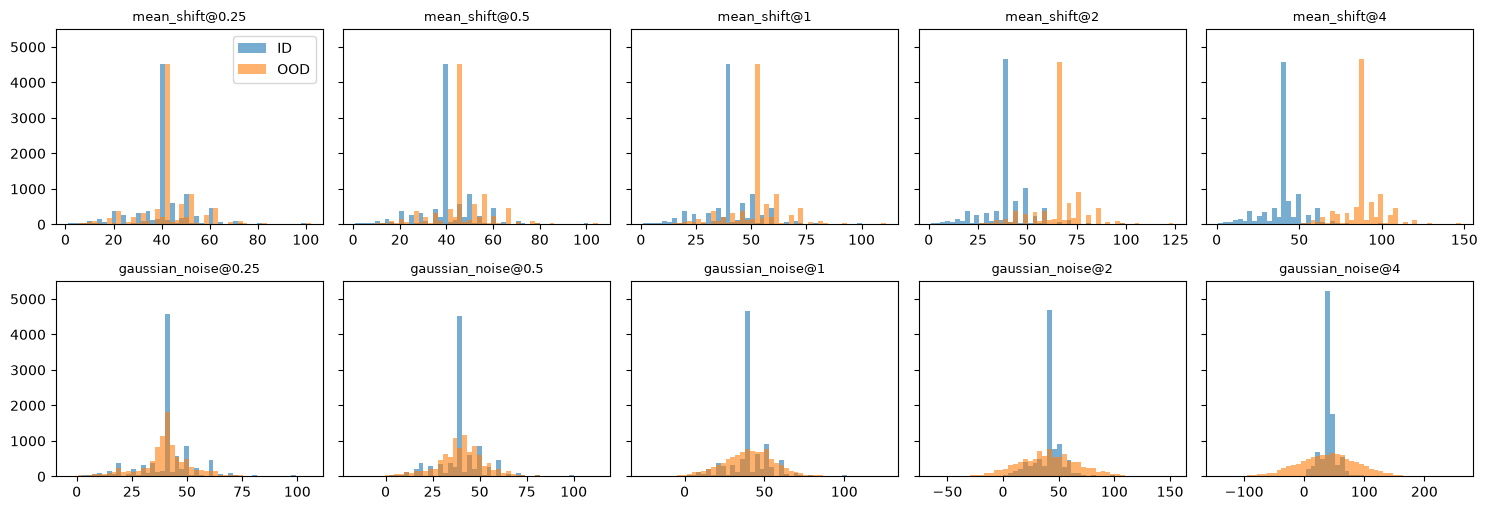

In [9]:
FEATURE = "hours-per-week"
fig, axes = plt.subplots(len(kinds), len(sevs), figsize=(3 * len(sevs), 2.6 * len(kinds)), sharey=True)
for i, kind in enumerate(kinds):
    for j, sev in enumerate(sevs):
        s = next(s for s in shifts if s.kind == kind and s.severity == sev)
        X_ood = s.apply(X_id, seed=SEED)
        edges = np.histogram_bin_edges(np.r_[X_id[FEATURE], X_ood[FEATURE]], bins=50)
        ax = axes[i, j]
        ax.hist(X_id[FEATURE], bins=edges, alpha=0.6, label="ID")
        ax.hist(X_ood[FEATURE], bins=edges, alpha=0.6, label="OOD")
        ax.set_title(s.name, fontsize=9)
axes[0, 0].legend()
plt.tight_layout(); plt.show()

## 3. How detectable is each scenario?
A **classifier two-sample test (C2ST)**: a LightGBM classifier is trained (5-fold, grouped so a row and its shifted copy never straddle train/test) to tell ID rows from shifted rows.
AUROC ≈ 0.5 means indistinguishable, ≈ 1.0 means trivially separable. It is a *supervised* reference (it sees OOD labels), so unsupervised detectors should not be expected to beat it by much.
Its job here: show which severities are informative, so the benchmark spans *hard → easy* instead of only easy cases.

In [10]:
rows = []
for s in shifts:
    X_ood = s.apply(X_id, seed=SEED)
    rows.append({"kind": s.kind, "severity": s.severity,
                 "c2st_auroc": shift_detectability(X_id, X_ood, seed=SEED)})
det = pd.DataFrame(rows)
det.pivot(index="kind", columns="severity", values="c2st_auroc").round(3)

severity,0.25,0.50,1.00,2.00,4.00
kind,,,,,
gaussian_noise,0.901,0.927,0.950,0.98,0.995
mean_shift,0.988,0.993,0.996,1.00,1.000


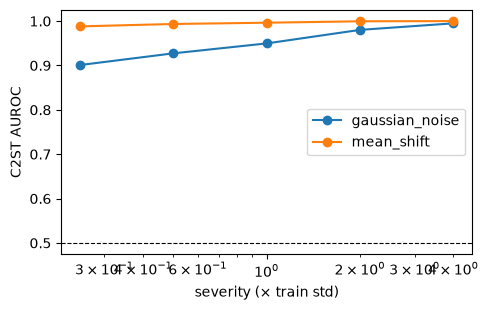

In [11]:
fig, ax = plt.subplots(figsize=(5, 3.2))
for kind, g in det.groupby("kind"):
    ax.plot(g["severity"], g["c2st_auroc"], "o-", label=kind)
ax.axhline(0.5, color="k", ls="--", lw=0.8)
ax.set_xscale("log"); ax.set_xlabel("severity (× train std)"); ax.set_ylabel("C2ST AUROC")
ax.legend(); plt.tight_layout(); plt.show()

## 4. Why the defaults are what they are
The same two severities with `dense_numeric` (default) versus `all_numeric` (includes zero-inflated features).
If `all_numeric` is ≈ 1.0 even at the smallest severity, the zero-inflated features alone make every scenario trivial.

In [12]:
rows = []
for features in ["dense_numeric", "all_numeric"]:
    for kind in kinds:
        for sev in (0.25, 1.0):
            s = CovariateShift(kind, sev, features).fit(splits.train.X, ds.numeric)
            rows.append({"features": features, "kind": kind, "severity": sev,
                         "c2st_auroc": shift_detectability(X_id, s.apply(X_id, seed=SEED), seed=SEED)})
pd.DataFrame(rows).pivot_table(index=["features", "kind"], columns="severity", values="c2st_auroc").round(3)

severity                       0.25   1.00
features      kind                        
all_numeric   gaussian_noise  1.000  1.000
              mean_shift      1.000  1.000
dense_numeric gaussian_noise  0.901  0.950
              mean_shift      0.988  0.996

## 5. Notes to carry into `docs/decisions.md`
- Does the grid span from near-chance to saturation for **both** kinds? If even 0.25 is ≈ 1.0 on the real data, add smaller severities (0.1, 0.05); if 4.0 is far from 1.0, add larger ones.
- Which numeric features did the `dense_numeric` rule drop on the real Adult? Does that match your expectation?
- Scenarios are rebuilt deterministically from the seed, so nothing needs to be saved to `data/ood/`.